In [5]:
import pandas as pd
import json
import numpy as np
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, r2_score
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
%config IPCompleter.greedy = True
import matplotlib.pyplot as plt
%matplotlib inline

# Задание

Скачайте данные об отзывов клиентов банков https://disk.yandex.ru/d/2o1ZmkzBQMANqw. Считайте первые 100 тысяч строк в таблицу.

In [6]:
df = pd.read_csv('reviews_banks.csv', nrows=100_000)
df.shape

(75000, 4)

In [7]:
df.head(10)

,bank,feeds,grades,date
0,ubrr,"Много лет являюсь клиентом этого банка, но пос...",1.0,16.02.2017 16:10
1,fk_otkritie,"Г. Ростов-на-Дону, ул. Ленина, 48. Были 10.12....",2.0,13.12.2016 1:05
2,alfabank,Здравствуйте!Ранее уже оставлял отзыв о вашем ...,NaN,28.06.2019 13:54
3,vtb,Обращаюсь к Вам с жалобой на незаконное списан...,NaN,15.07.2020 14:54
4,promsvyazbank,"Имею потребительский кредит, взятый в Связь-ба...",2.0,04.08.2020 6:38
5,pochtabank,Брала кредит на стиральную машину. Все платила...,NaN,09.04.2015 17:19
6,otpbank,"Откуда взялся долг по кредитной карте, если я ...",NaN,28.01.2021 13:20
7,homecreditbank,Хочу выразить глубокую благодарность всем сотр...,5.0,19.04.2015 20:11
8,vtb,"6 марта 2019г. В 10:33 при проходе в метро ""Ку...",2.0,28.03.2019 18:36
9,fk_otkritie,"Уважаемый Бинбанк, если у вас имеются какие-ли...",NaN,31.08.2018 16:48


## Задание

Удалите из таблицы df строки, где целевая переменная grades неизвестна.

In [8]:
df = df.dropna(subset=['grades']).reset_index(drop=True)
print(df.shape, df['grades'].isna().sum())

(51476, 4) 0


Постройте гистограмму распределения для столбца grades.

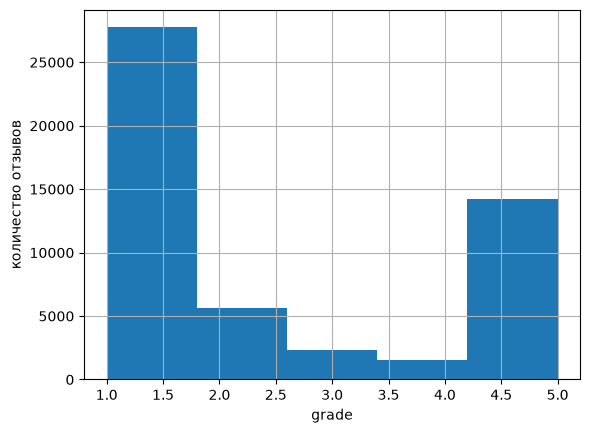

In [9]:
df['grades'].hist(bins=5)
plt.xlabel('grade'); plt.ylabel('количество отзывов')
plt.show()

## Задание

Для каждого банка (bank) вычислите средний grade.

Отсортируйте результаты в порядке убывания этого среднего.

In [10]:
df.groupby('bank')['grades'].mean().sort_values(ascending=False)

bank
interprombank     4.584000
modulbank         4.060071
talkbank          4.050000
tochka            4.000000
nordea            3.733333
                    ...   
rncb              1.533333
v-express-bank    1.477679
atb               1.415730
bnpparibasbank    1.333333
roundbank         1.156863
Name: grades, Length: 69, dtype: float64

## Задание

При помощи TfidfVectorizer с гиперпараметрами
`min_df=5, max_df=1.0, ngram_range=(1, 1)`
закодируйте столбец `feeds`.

Преобразованный столбец сохраните в переменную `descr`.

In [11]:
tfidf = TfidfVectorizer(min_df=5, max_df=1.0, ngram_range=(1, 1))
descr = tfidf.fit_transform(df['feeds'])   # fit учит словарь и IDF, transform кодирует тексты

In [12]:
print(descr.shape)

(51476, 45602)


## Задание

При помощи `train_test_split` разбейте данные на тренировочную и тестовую части:

* в качестве матрицы признаков используйте закодированные отзывы `descr`

* вектор ответов - `df['grades']`

В тест отправьте 20% данных, зафиксируйте `random_state=42`.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    descr, df['grades'], test_size=0.2, random_state=42
)

## Задание

Будем решать задачу прогноза grades как задачу регрессии.

Обучите Ridge-регрессию (с гиперпараметрами по умолчанию) на тренировочных данных и выведите качество модели ($R^2$) на трейне и на тесте.

In [14]:
clf = Ridge()
clf.fit(X_train, y_train)
print('R2 train:', r2_score(y_train, clf.predict(X_train)))
print('R2 test: ', r2_score(y_test, clf.predict(X_test)))

R2 train: 0.8531262082904314
R2 test:  0.7288874281146286


Посмотрим как работает ваша модель.

In [15]:
clf.predict(tfidf.transform(["Отличный банк! Очень нравится!"]))

array([5.61120078])

In [16]:
clf.predict(tfidf.transform(["Отвратительное обслуживание, я разочарована."]))

array([0.66945973])

## Задание

Выведите на экран в виде pd.DataFrame топ-10 признаков с наибольшим положительным весом, а затем топ-10 признаков с наибольшим отрицательным весом.

In [17]:
coefs = pd.DataFrame({
    'word': tfidf.get_feature_names_out(),
    'weight': clf.coef_,
}).sort_values('weight', ascending=False).reset_index(drop=True)

In [18]:
coefs.head(10)

,word,weight
0,спасибо,5.398755
1,благодарность,4.016649
2,приятно,3.567105
3,поблагодарить,3.484233
4,доволен,3.272951
5,благодарю,3.142127
6,благодарен,3.108240
7,лучший,2.894770
8,быстро,2.872355
9,понравилось,2.828092


In [19]:
coefs.tail(10)[::-1]

,word,weight
45601,не,-2.511229
45600,отвратительное,-2.352227
45599,обман,-2.316048
45598,никому,-2.139479
45597,отвратительный,-2.003502
45596,ужасное,-1.897409
45595,закрою,-1.888964
45594,поведение,-1.776024
45593,отказано,-1.770188
45592,требую,-1.763254


## Бонус

Поэкспериментируйте с настройками:

* можно настраивать гиперпараметры в Tf-Idf кодировщике (или попробовать CountVectorizer)

* можно настраивать (при помощи GridSearchCV) гиперпараметр регуляризации `C` у Ridge-регрессии (или попробовать Lasso-регрессию).

Ваша цель - добиться наилучшего качества $R^2$ на тестовых данных.

In [20]:
pipe_params = {'alpha': [0.1, 0.3, 1, 3]}
best = None
for ngram in [(1, 1), (1, 2)]:
    tf = TfidfVectorizer(min_df=5, ngram_range=ngram, sublinear_tf=True)
    X = tf.fit_transform(df['feeds'])
    Xtr, Xte, ytr, yte = train_test_split(X, df['grades'], test_size=0.2, random_state=42)
    gs = GridSearchCV(Ridge(), pipe_params, scoring='r2', cv=3)
    gs.fit(Xtr, ytr)
    score = r2_score(yte, gs.predict(Xte))
    print(ngram, gs.best_params_, 'R2 test =', round(score, 4))

(1, 1) {'alpha': 3} R2 test = 0.7351
(1, 2) {'alpha': 1} R2 test = 0.7493


## Задание

Закодируем каждый отзыв таким образом:
- вычислим w2v-вектор для каждого слова
- усредним полученные w2v-векторы внутри каждого отзыва


In [21]:
# gensim и pymorphy3 установил через requirements.txt, работю в VSCode+envs
# !pip install gensim pymorphy3 pymorphy3-dicts-ru -q

In [22]:
import os, re
from functools import lru_cache
import gensim.downloader as api
import pymorphy3
from sklearn.metrics.pairwise import cosine_similarity

# модель лежит в папке models/ рядом с ноутбуком (если её нет - api.load скачает её туда сам, ~200 МБ)
api.BASE_DIR = os.path.abspath('models')
api.base_dir = api.BASE_DIR

model = api.load("word2vec-ruscorpora-300")
print(len(model), model.vector_size)
model.most_similar('банк_NOUN', topn=3)

184973 300


[('банковский_ADJ', 0.7502143979072571),
 ('сбербанк_NOUN', 0.742872953414917),
 ('кредитный_ADJ', 0.700251579284668)]

In [23]:
# тут уже ИИ помогал
# ruscorpora обучена на текстах вида "лемма_ЧАСТЬРЕЧИ" (например "банк_NOUN"),
# поэтому слова надо привести к начальной форме и пометить частью речи в формате Universal POS
morph = pymorphy3.MorphAnalyzer()
POS = {'NOUN': 'NOUN', 'ADJF': 'ADJ', 'ADJS': 'ADJ', 'COMP': 'ADJ', 'VERB': 'VERB', 'INFN': 'VERB',
       'PRTF': 'VERB', 'PRTS': 'VERB', 'GRND': 'VERB', 'ADVB': 'ADV', 'NUMR': 'NUM', 'NPRO': 'PRON'}

@lru_cache(maxsize=None)          # слова повторяются, разбор каждого считаем один раз
def to_token(word):
    p = morph.parse(word)[0]
    return f"{p.normal_form}_{POS.get(p.tag.POS, 'X')}"

def get_average_vector(text, model):
    words = re.findall(r'[а-яё]+', text.lower())
    word_vectors = []
    for word in words:
        tok = to_token(word)
        if tok in model:  # проверяем, есть ли слово в модели
            word_vectors.append(model[tok])
    if len(word_vectors) == 0:
        return np.zeros(model.vector_size)  # если нет слов в модели, возвращаем нулевой вектор
    return np.mean(word_vectors, axis=0)

Протестируйте функцию выше:
- возьмите один любой отзыв на банк и выведите его на экран
- с помощью косинусного расстояния найдите три ближайших к нему отзыва (считайте косинусное расстояние между w2v-векторами отзывов) и выведите их на экран

In [24]:
vectors = np.vstack([get_average_vector(t, model) for t in df['feeds']])

i = 0
print('ОТЗЫВ:', df['feeds'][i][:500], '\n')

sims = cosine_similarity(vectors[i:i+1], vectors)[0]
sims[i] = -1                        # исключаем сам отзыв
for j in sims.argsort()[::-1][:3]:  # индексы трёх наибольших сходств
    print(f'--- cos={sims[j]:.3f}:', df['feeds'][j][:500], '\n')

ОТЗЫВ: Много лет являюсь клиентом этого банка, но последний визит просто оставил негатив в душе! Как клиенту банка мне была предложена кредитная карта, подумав над предложением, решила ее оформить. 09.02 пошла в офис по адресу Екатеринбург, б. Ак. Бардина,17, оформили заявку, сказали ждать 15 минут, после одобрения пришла оформлять. Специалист, который со мной работала, сказала, что нужно за обслуживание карты заплатить 900 рублей, я ее спросила почему не предупредили меня заранее, на что она мне с ухм 

--- cos=0.967: Доброго времени суток дорогие друзья!Несколько дней назад я получил предложение о приобретении некоторого актива, от которого было грех отказываться. Был только один подводный камень, совсем немножко не вписывался в бюджет покупки, в связи с чем, было принято решение о закрытии этой дыры в бюджете путем привлечения заемных средств. Ну, сказано – сделано, первым делом пошел в банк, в котором я являюсь постоянным клиентом, однако там, договорится не удалось (об этом походе